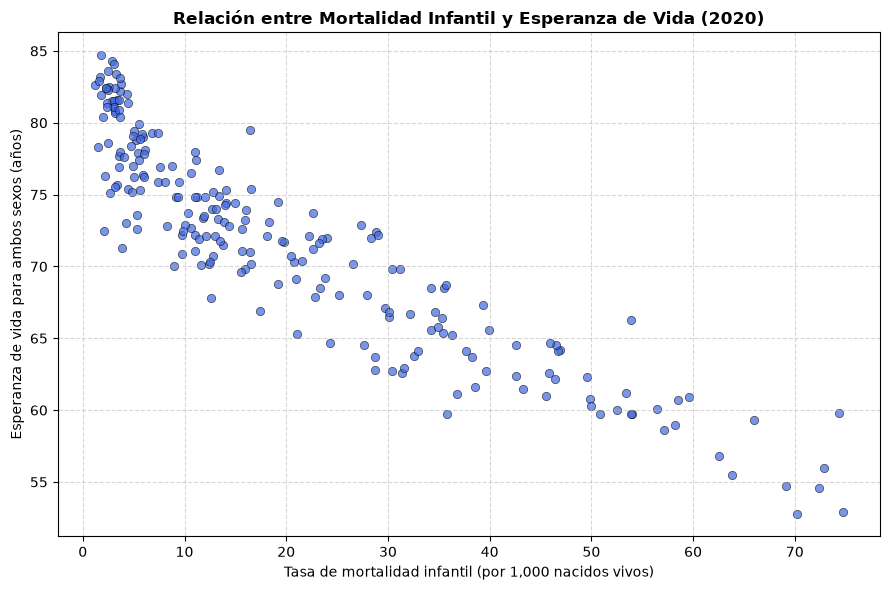

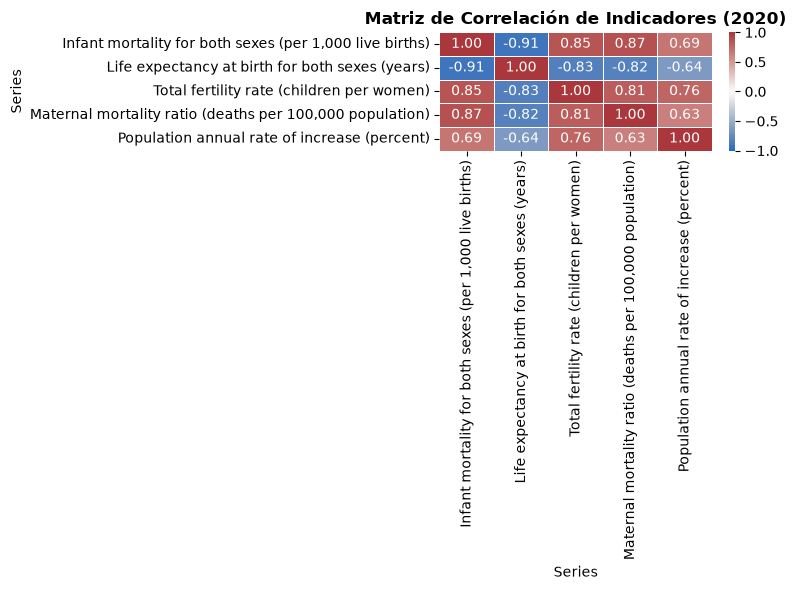

In [11]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

df = pd.read_csv(
    "SYB66_246_202310_Population Growth, Fertility and Mortality Indicators.csv",
    encoding="latin-1",
    skiprows=2,
)
df.columns = [
    "Region/Country/Area",
    "Country_Name",
    "Year",
    "Series",
    "Value",
    "Footnotes",
    "Source",
]

df_2020 = df[df["Year"] == 2020].copy()
df_2020["Value"] = pd.to_numeric(df_2020["Value"], errors="coerce")

df_pivot = df_2020.pivot(
    index=["Region/Country/Area", "Country_Name"],
    columns="Series",
    values="Value",
).reset_index()

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df_pivot,
    x="Infant mortality for both sexes (per 1,000 live births)",
    y="Life expectancy at birth for both sexes (years)",
    color="royalblue",
    alpha=0.7,
    edgecolor="k",
)
plt.title(
    "Relación entre Mortalidad Infantil y Esperanza de Vida (2020)",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Tasa de mortalidad infantil (por 1,000 nacidos vivos)")
plt.ylabel("Esperanza de vida para ambos sexos (años)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

cols_of_interest = [
    "Infant mortality for both sexes (per 1,000 live births)",
    "Life expectancy at birth for both sexes (years)",
    "Total fertility rate (children per women)",
    "Maternal mortality ratio (deaths per 100,000 population)",
    "Population annual rate of increase (percent)",
]
df_subset = df_pivot.dropna(subset=cols_of_interest)
corr_matrix = df_subset[cols_of_interest].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix, annot=True, cmap="vlag", fmt=".2f", vmin=-1, vmax=1, linewidths=0.5
)
plt.title(
    "Matriz de Correlación de Indicadores (2020)", fontsize=12, fontweight="bold"
)
plt.tight_layout()
plt.show()